<a href="https://colab.research.google.com/github/owel569/Atelier2-CASANDRA/blob/main/04_GPU_PyTorch_TorchCompile.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 – Pipeline GPU n°2 : PyTorch → torch.compile / TorchScript → CUDA → GPU

| Couche | Technologie |
|---|---|
| Haut niveau | PyTorch (ResNet-18 pré-entraîné ImageNet) |
| Format du modèle | graphe PyTorch 2 (Dynamo/FX) ; variante : TorchScript |
| Middle level | compilation par PyTorch (Inductor : fusion d'opérateurs, génération de kernels Triton) |
| Bas niveau | CUDA / cuDNN (convolutions) + kernels Triton |
| Matériel | GPU Google Colab (NVIDIA) |

Pipeline **principal** : `torch.compile` (Inductor). Variante : TorchScript. Baseline : PyTorch eager sur GPU.

**Runtime Colab obligatoire : GPU.**

In [21]:
!nvidia-smi
!pip -q install nvidia-ml-py

Tue Nov 24 13:31:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P0             28W /   70W |     535MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [1]:
import os, sys, time, json, hashlib, platform, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torchvision
from torchvision import transforms, datasets, models
from torchvision.transforms import InterpolationMode

# ====== PARAMÈTRES EXPÉRIMENTAUX (NE PAS MODIFIER : identiques dans les 4 notebooks) ======
SEED       = 42     # graine : même sous-ensemble de 50 images partout
N_IMAGES   = 50     # nombre d'images CIFAR-10 (jeu de test)
BATCH_SIZE = 10     # taille de batch (50 = 5 batchs)
IMG_SIZE   = 224    # taille d'entrée de ResNet-18
N_WARMUP   = 5      # passes de chauffe (exclues des mesures)
N_RUNS     = 5      # exécutions indépendantes (>= 3 exigé par l'énoncé)
N_PASSES   = 10     # nombre de passes sur les 50 images par exécution (mesures plus stables, énergie mesurable)
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

torch 2.14.1+cu130 | torchvision 0.29.1+cu130


In [3]:
assert torch.cuda.is_available(), "Active un runtime GPU dans Colab !"

In [4]:
# ---------- Données : 50 images du jeu de test CIFAR-10 ----------
CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
                 "dog", "frog", "horse", "ship", "truck"]

# ResNet-18 a été pré-entraîné sur ImageNet (1000 classes), pas sur CIFAR-10.
# Pour calculer une précision Top-1 sur 10 classes, on associe chaque classe CIFAR-10
# à un groupe de classes ImageNet. Score d'une classe CIFAR = max des logits de son groupe.
IMAGENET_GROUPS = {
    "airplane":   [404, 895, 908],
    "automobile": [436, 468, 511, 609, 627, 656, 661, 751, 817],
    "bird":       list(range(7, 25)) + list(range(80, 101)) + list(range(127, 147)),
    "cat":        [281, 282, 283, 284, 285],
    "deer":       [351, 352, 353],
    "dog":        list(range(151, 269)),
    "frog":       [30, 31, 32],
    "horse":      [339, 603],
    "ship":       [403, 472, 484, 510, 554, 625, 628, 724, 780, 814, 833, 871, 914],
    "truck":      [555, 569, 675, 717, 734, 864, 867],
}
GROUPS = [np.array(IMAGENET_GROUPS[c]) for c in CIFAR_CLASSES]

def to_cifar(logits):
    """logits ImageNet (N,1000) -> classe CIFAR-10 prédite (N,)"""
    scores = np.stack([logits[:, g].max(axis=1) for g in GROUPS], axis=1)
    return scores.argmax(axis=1)

# Prétraitement identique à celui du pré-entraînement ImageNet : redimensionnement + normalisation
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

ds = datasets.CIFAR10(root="data", train=False, download=True)
idx = np.random.RandomState(SEED).choice(len(ds), N_IMAGES, replace=False).astype(np.int64)
labels = np.array([ds[int(i)][1] for i in idx])
X = torch.stack([tfm(ds[int(i)][0]) for i in idx]).contiguous()     # (50, 3, 224, 224) float32
SUBSET_HASH = hashlib.md5(idx.tobytes()).hexdigest()
print("X :", tuple(X.shape), X.dtype, "| hash du sous-ensemble :", SUBSET_HASH)
print("Répartition des classes :", dict(zip(CIFAR_CLASSES, np.bincount(labels, minlength=10).tolist())))

# Vérification visuelle des groupes (noms ImageNet réellement associés)
IN_NAMES = models.ResNet18_Weights.IMAGENET1K_V1.meta["categories"]
for c, g in zip(CIFAR_CLASSES, GROUPS):
    print(f"{c:11s} <- {len(g):3d} classes ImageNet, ex. : {[IN_NAMES[i] for i in g[:4]]}")

100%|██████████| 170M/170M [29:08<00:00, 97.5kB/s]


X : (50, 3, 224, 224) torch.float32 | hash du sous-ensemble : 3fb089145f7501be08d1825dfa25324f
Répartition des classes : {'airplane': 4, 'automobile': 4, 'bird': 7, 'cat': 5, 'deer': 3, 'dog': 9, 'frog': 5, 'horse': 4, 'ship': 5, 'truck': 4}
airplane    <-   3 classes ImageNet, ex. : ['airliner', 'warplane', 'wing']
automobile  <-   9 classes ImageNet, ex. : ['beach wagon', 'cab', 'convertible', 'jeep']
bird        <-  59 classes ImageNet, ex. : ['cock', 'hen', 'ostrich', 'brambling']
cat         <-   5 classes ImageNet, ex. : ['tabby', 'tiger cat', 'Persian cat', 'Siamese cat']
deer        <-   3 classes ImageNet, ex. : ['hartebeest', 'impala', 'gazelle']
dog         <- 118 classes ImageNet, ex. : ['Chihuahua', 'Japanese spaniel', 'Maltese dog', 'Pekinese']
frog        <-   3 classes ImageNet, ex. : ['bullfrog', 'tree frog', 'tailed frog']
horse       <-   2 classes ImageNet, ex. : ['sorrel', 'horse cart']
ship        <-  13 classes ImageNet, ex. : ['aircraft carrier', 'canoe', 'catam

In [13]:
# ---------- Modèle PyTorch pré-entraîné + référence (eager, CPU, FP32) ----------
WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1

def load_model():
    return models.resnet18(weights=WEIGHTS).eval()

ref_model = load_model()
with torch.inference_mode():
    ref_logits = torch.cat([ref_model(b) for b in X.split(BATCH_SIZE)]).numpy()
ref_pred = to_cifar(ref_logits)
print("Top-1 de référence (PyTorch eager CPU FP32) :", (ref_pred == labels).mean())

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 194MB/s]


Top-1 de référence (PyTorch eager CPU FP32) : 0.66


In [6]:
# ---------- Informations sur l'environnement (à citer dans le rapport) ----------
def _cpu_name():
    try:
        for l in open("/proc/cpuinfo"):
            if l.startswith("model name"):
                return l.split(":")[1].strip()
    except Exception:
        pass
    return platform.processor()

ENV = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cpu": _cpu_name(),
    "cpu_count": os.cpu_count(),
    "torch_threads": torch.get_num_threads(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
}
print(json.dumps(ENV, indent=2))

{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "cpu": "Intel(R) Xeon(R) CPU @ 2.00GHz",
  "cpu_count": 2,
  "torch_threads": 1,
  "gpu": "Tesla T4",
  "cuda": "13.0",
  "cudnn": 92800
}


In [7]:
# ---------- Mesure d'énergie (best effort) ----------
class EnergyMeter:
    """GPU : compteur d'énergie NVML (mJ).  CPU : compteur Intel RAPL si lisible.
    Si indisponible -> None (l'énoncé autorise 'lorsque les mesures sont disponibles')."""
    def __init__(self, kind):
        self.kind, self.ok = kind, False
        if kind == "gpu":
            try:
                import pynvml
                pynvml.nvmlInit()
                self.nv = pynvml
                self.h = pynvml.nvmlDeviceGetHandleByIndex(0)
                pynvml.nvmlDeviceGetTotalEnergyConsumption(self.h)
                self.ok = True
            except Exception as e:
                print("[énergie GPU indisponible]", e)
        else:
            self.p = "/sys/class/powercap/intel-rapl:0/"
            try:
                open(self.p + "energy_uj").read()
                self.max_j = int(open(self.p + "max_energy_range_uj").read()) / 1e6
                self.ok = True
            except Exception as e:
                print("[énergie CPU (RAPL) indisponible]", e)

    def read(self):
        if not self.ok: return None
        if self.kind == "gpu":
            return self.nv.nvmlDeviceGetTotalEnergyConsumption(self.h) / 1000.0
        return int(open(self.p + "energy_uj").read()) / 1e6

    def delta(self, a, b):
        if a is None or b is None: return None
        d = b - a
        if self.kind == "cpu" and d < 0: d += self.max_j
        return d


METRICS = ["throughput", "pass_s", "batch_ms", "img_ms", "energy_j", "energy_per_img_j", "power_w"]

def _stats(runs, key):
    v = [r[key] for r in runs if r.get(key) is not None]
    if len(v) == 0: return None
    v = np.array(v, dtype=float)
    return {"mean": float(v.mean()), "std": float(v.std(ddof=1)) if len(v) > 1 else 0.0,
            "min": float(v.min()), "max": float(v.max())}


def benchmark(pid, label, group, hw, infer_fn, build_time_s=None, is_main=True, extra=None):
    """infer_fn(batch_cpu_tensor) -> logits numpy (B,1000) sur CPU.
    La mesure inclut donc les transferts hôte<->device (même définition pour les 4 pipelines)."""
    batches = list(X.split(BATCH_SIZE))
    print(f"\n=== {label} ===")
    for _ in range(N_WARMUP):                       # chauffe (hors mesure)
        for b in batches: infer_fn(b)
    meter, runs, last_logits = EnergyMeter(hw), [], None
    n = N_IMAGES * N_PASSES
    for r in range(N_RUNS):
        lat, e0, t0 = [], meter.read(), time.perf_counter()
        for _ in range(N_PASSES):
            outs = []
            for b in batches:
                tb = time.perf_counter()
                outs.append(infer_fn(b))
                lat.append(time.perf_counter() - tb)
        t = time.perf_counter() - t0
        E = meter.delta(e0, meter.read())
        logits = np.concatenate(outs)
        if last_logits is not None:
            assert np.abs(logits - last_logits).max() < 1e-2, "sorties instables entre exécutions"
        last_logits = logits
        runs.append({
            "throughput": n / t,                   # images / s
            "pass_s": t / N_PASSES,                # temps pour traiter les 50 images (s)
            "batch_ms": 1000 * float(np.mean(lat)),# latence moyenne par batch (ms)
            "img_ms": 1000 * t / n,                # latence moyenne par image (ms)
            "energy_j": E,
            "energy_per_img_j": None if E is None else E / n,
            "power_w": None if E is None else E / t,
        })
        print(f"  run {r+1}/{N_RUNS} : {runs[-1]['throughput']:8.1f} img/s | {runs[-1]['pass_s']*1000:7.1f} ms / 50 img")
    pred = to_cifar(last_logits)
    result = {
        "id": pid, "label": label, "group": group, "hw": hw, "is_main": is_main,
        "build_time_s": build_time_s, "env": ENV, "extra": extra or {},
        "config": dict(SEED=SEED, N_IMAGES=N_IMAGES, BATCH_SIZE=BATCH_SIZE, N_WARMUP=N_WARMUP,
                       N_RUNS=N_RUNS, N_PASSES=N_PASSES, SUBSET_HASH=SUBSET_HASH),
        "runs": runs,
        "stats": {k: _stats(runs, k) for k in METRICS},
        "accuracy": {
            "top1": float((pred == labels).mean()),
            "agreement_with_ref": float((pred == ref_pred).mean()),
            "imagenet_argmax_agreement": float((last_logits.argmax(1) == ref_logits.argmax(1)).mean()),
            "max_abs_logit_diff_vs_ref": float(np.abs(last_logits - ref_logits).max()),
        },
        "predictions": pred.tolist(), "labels": labels.tolist(),
    }
    with open(f"{RESULTS_DIR}/{pid}.json", "w") as f:
        json.dump(result, f, indent=1)
    s = result["stats"]
    print(f"  -> débit {s['throughput']['mean']:.1f} ± {s['throughput']['std']:.1f} img/s | "
          f"Top-1 {result['accuracy']['top1']:.2%} | accord avec réf. {result['accuracy']['agreement_with_ref']:.2%}")
    return result


def summary_table(results):
    rows = []
    for r in results:
        row = {"pipeline": r["label"], "build (s)": r["build_time_s"]}
        for k, name in [("throughput", "img/s"), ("pass_s", "s/50img"), ("batch_ms", "ms/batch"), ("energy_per_img_j", "J/img")]:
            s = r["stats"][k]
            row[name + " moy"] = None if s is None else s["mean"]
            row[name + " std"] = None if s is None else s["std"]
            row[name + " min"] = None if s is None else s["min"]
            row[name + " max"] = None if s is None else s["max"]
        row["Top-1"] = r["accuracy"]["top1"]
        row["accord réf."] = r["accuracy"]["agreement_with_ref"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("pipeline").T


def plot_own(results, fname):
    """Graphiques propres à ce notebook (la comparaison des 4 pipelines est dans le notebook 05)."""
    labs = [r["label"] for r in results]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    m = [r["stats"]["throughput"]["mean"] for r in results]
    s = [r["stats"]["throughput"]["std"] for r in results]
    ax[0].bar(labs, m, yerr=s, capsize=5, color="tab:blue"); ax[0].set_ylabel("images / s"); ax[0].set_title("Débit (moyenne ± écart-type)")
    m = [r["stats"]["pass_s"]["mean"] * 1000 for r in results]
    s = [r["stats"]["pass_s"]["std"] * 1000 for r in results]
    ax[1].bar(labs, m, yerr=s, capsize=5, color="tab:orange"); ax[1].set_ylabel("ms pour 50 images"); ax[1].set_title("Temps d'inférence (50 images)")
    for r in results:
        ax[2].plot(range(1, N_RUNS + 1), [x["throughput"] for x in r["runs"]], "o-", label=r["label"])
    ax[2].set_xlabel("exécution"); ax[2].set_ylabel("images / s"); ax[2].set_title("Variabilité run par run"); ax[2].legend(fontsize=7)
    for a in ax[:2]: a.tick_params(axis="x", rotation=15)
    plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig(f"figures/{fname}", dpi=150); plt.show()


def download_results():
    try:
        from google.colab import files
        import shutil
        shutil.make_archive("results_export", "zip", RESULTS_DIR)
        files.download("results_export.zip")
    except Exception as e:
        print("Hors Colab / téléchargement impossible :", e, "-> récupère le dossier results/ à la main.")

In [8]:
def make_torch_infer(m, device):
    def f(x):
        with torch.inference_mode():
            return m(x.to(device)).cpu().numpy()
    return f

## 1. Baseline : PyTorch eager (GPU)

In [14]:
m_eager = load_model().to("cuda")
res_eager = benchmark("gpu_pytorch_eager", "GPU baseline : PyTorch eager", "baseline", "gpu",
                      make_torch_infer(m_eager, "cuda"), build_time_s=0.0, is_main=False)


=== GPU baseline : PyTorch eager ===
  run 1/5 :    922.9 img/s |    54.2 ms / 50 img
  run 2/5 :    920.0 img/s |    54.3 ms / 50 img
  run 3/5 :    921.7 img/s |    54.2 ms / 50 img
  run 4/5 :    916.9 img/s |    54.5 ms / 50 img
  run 5/5 :    923.8 img/s |    54.1 ms / 50 img
  -> débit 921.1 ± 2.7 img/s | Top-1 66.00% | accord avec réf. 100.00%


## 2. Pipeline principal : `torch.compile` (Inductor)
Le 1er appel compile le graphe (fusions + kernels Triton) ; la durée est mesurée séparément.

In [15]:
import torch._dynamo
torch._dynamo.reset()
m_c = torch.compile(load_model().to("cuda"), backend="inductor")
infer_c = make_torch_infer(m_c, "cuda")
t0 = time.perf_counter()
infer_c(X[:BATCH_SIZE])
compile_s = time.perf_counter() - t0
print(f"Temps de compilation (1er appel) : {compile_s:.1f}s")

res_compile = benchmark("gpu2_pytorch_torchcompile", "GPU 2 : PyTorch→torch.compile (Inductor)", "gpu2", "gpu",
                        infer_c, build_time_s=compile_s, is_main=True,
                        extra={"backend": "inductor", "compile_s": compile_s})

W1124 13:21:49.911000 472 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


Temps de compilation (1er appel) : 19.4s

=== GPU 2 : PyTorch→torch.compile (Inductor) ===
  run 1/5 :    884.8 img/s |    56.5 ms / 50 img
  run 2/5 :    887.9 img/s |    56.3 ms / 50 img
  run 3/5 :    882.4 img/s |    56.7 ms / 50 img
  run 4/5 :    873.1 img/s |    57.3 ms / 50 img
  run 5/5 :    874.1 img/s |    57.2 ms / 50 img
  -> débit 880.5 ± 6.6 img/s | Top-1 66.00% | accord avec réf. 100.00%


## 3. Variante : TorchScript (`trace` → `freeze` → `optimize_for_inference`)

In [16]:
t0 = time.perf_counter()
m_ts = torch.jit.trace(load_model().to("cuda"), X[:BATCH_SIZE].to("cuda"))
m_ts = torch.jit.freeze(m_ts)
m_ts = torch.jit.optimize_for_inference(m_ts)
infer_ts = make_torch_infer(m_ts, "cuda")
for _ in range(3): infer_ts(X[:BATCH_SIZE])
ts_s = time.perf_counter() - t0
print(f"Mise en place TorchScript : {ts_s:.1f}s")

res_ts = benchmark("gpu2_pytorch_torchscript", "GPU 2 (variante) : PyTorch→TorchScript", "gpu2", "gpu",
                   infer_ts, build_time_s=ts_s, is_main=False, extra={"variant": "torchscript+freeze+optimize_for_inference"})

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_freeze.py:106: FutureWarning: `torch.jit.freeze` is deprecated. Please use `torch.compile` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_freeze.py:230: FutureWarning: `torch.jit.optimize_for_inference` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


Mise en place TorchScript : 1.5s

=== GPU 2 (variante) : PyTorch→TorchScript ===
  run 1/5 :   1062.1 img/s |    47.1 ms / 50 img
  run 2/5 :   1059.9 img/s |    47.2 ms / 50 img
  run 3/5 :   1049.7 img/s |    47.6 ms / 50 img
  run 4/5 :   1050.5 img/s |    47.6 ms / 50 img
  run 5/5 :   1047.6 img/s |    47.7 ms / 50 img
  -> débit 1053.9 ± 6.6 img/s | Top-1 66.00% | accord avec réf. 100.00%


## 4. Résumé et graphiques

In [17]:
summary_table([res_eager, res_compile, res_ts])

pipeline,GPU baseline : PyTorch eager,GPU 2 : PyTorch→torch.compile (Inductor),GPU 2 (variante) : PyTorch→TorchScript
build (s),0.000000,19.350266,1.465983
img/s moy,921.077402,880.473590,1053.933239
img/s std,2.739846,6.591876,6.559732
img/s min,916.884543,873.079200,1047.553200
img/s max,923.826906,887.944435,1062.070003
s/50img moy,0.054285,0.056790,0.047443
s/50img std,0.000162,0.000426,0.000295
s/50img min,0.054123,0.056310,0.047078
s/50img max,0.054532,0.057269,0.047730
ms/batch moy,10.855044,11.355854,9.486346


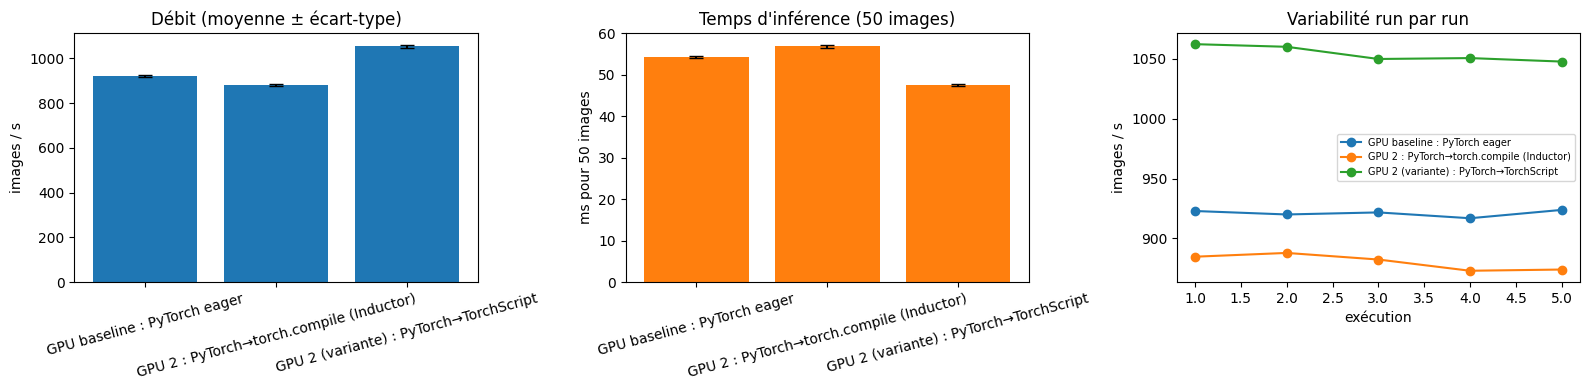

In [18]:
plot_own([res_eager, res_compile, res_ts], "gpu2_pytorch.png")

## 5. Analyse (à rédiger pour le rapport)
- Gain de `torch.compile` / TorchScript vs eager sur GPU ? Pour un modèle aussi petit que ResNet-18 avec batch 10, le gain est-il limité par les transferts CPU↔GPU ?
- Coût de compilation vs gain ?
- Comparer avec TensorRT (notebook 05).

In [22]:
download_results()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>